# PRCP-1006: Home Loan Default Prediction
### Capstone Project — Complete Data Analysis, Multi-Table Feature Engineering, Modeling & Reports
# 1. Business Case


**Dataset:** Home Credit Default Risk — a relational dataset spanning 7 tables: the main application file (`application_train.csv`, 307,511 loan applications) plus 6 supplementary tables tracking each client's prior credit history at other institutions and with Home Credit itself (`bureau.csv`, `bureau_balance.csv`, `POS_CASH_balance.csv`, `credit_card_balance.csv`, `previous_application.csv`, `installments_payments.csv`).

**Objective:**
1. Complete exploratory data analysis (EDA)
2. Engineer features from all 6 supplementary tables and merge into a single client-level feature set
3. Build and compare multiple classification models identifying default-risk factors and loan-eligible segments
4. Recommend the best model for production
5. Document challenges faced and techniques used

In [1]:
import os, gc, time, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

import pickle
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, recall_score, f1_score, roc_auc_score, average_precision_score, 
                                precision_score, precision_recall_curve, roc_curve, confusion_matrix, classification_report)
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

import xgboost as xgb
import lightgbm as lgb
import shap
import zipfile, glob

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)


RANDOM_STATE = 42
DATA_DIR = 'data'
ARTIFACT_DIR = 'artifacts'
MODEL_DIR = 'models'
os.makedirs(ARTIFACT_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

import psutil

def mem_gb():
    # Peak resident memory used so far, in GB (helps track the memory-constrained pipeline).
    process = psutil.Process()
    return process.memory_info().rss / (1024 ** 3) # convert bytes -> GB

print('Setup complete. Peak memory so far: %.2f GB' % mem_gb())

Setup complete. Peak memory so far: 0.26 GB


## 1. Data Dictionary (grain of every table)

| File | Grain | Rows (this dataset) |
|---|---|---|
| `application_train.csv` | 1 row per loan application (contains `TARGET`) | 307,511 |
| `bureau.csv` | 1 row per previous credit reported to the Credit Bureau, per client | 1,716,428 |
| `bureau_balance.csv` | 1 row per month of history, per bureau credit | 27,299,925 |
| `previous_application.csv` | 1 row per previous Home Credit application, per client | 1,670,214 |
| `POS_CASH_balance.csv` | 1 row per month of history, per previous POS/cash loan | 10,001,358 |
| `credit_card_balance.csv` | 1 row per month of history, per previous credit card | 3,840,312 |
| `installments_payments.csv` | 1 row per installment due/paid, per previous credit | 13,605,401 |

All six supplementary tables are many-to-one against `application_train` (via `SK_ID_CURR`, sometimes through `SK_ID_BUREAU`/`SK_ID_PREV`), so **Task 2 requires aggregating each one down to a single row per `SK_ID_CURR` before it can be joined** to the main table. That aggregation is treated as the core feature-engineering exercise below, combined with a light EDA pass over each table (its size makes a full standalone EDA pass wasteful — every table is read exactly once).


## 2. Task 1 (Part A) — EDA on the main application table

In [2]:
app = pd.read_csv(os.path.join(DATA_DIR, 'application_train.csv'))

# downcast to float32/int32 immediately - this table alone has 122 columns
for c in app.select_dtypes(include=['float64']).columns:
    app[c] = app[c].astype('float32')
for c in app.select_dtypes(include=['int64']).columns:
    app[c] = app[c].astype('int32')

print('Shape: ', app.shape)
app.head()

Shape:  (307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
app.info(memory_usage='deep', max_cols=0)
print('\nMemory footprint : %.2f GB' % mem_gb())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float32(65), int32(41), object(16)
memory usage: 380.6 MB

Memory footprint : 0.43 GB


TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


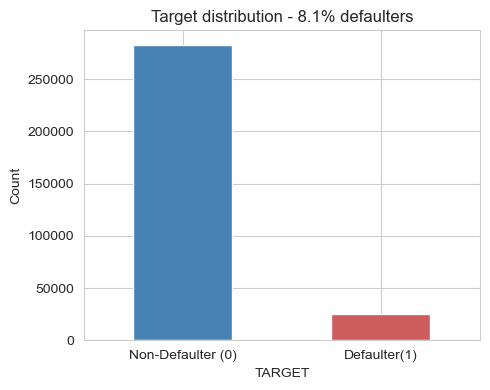

In [4]:
target_counts = app['TARGET'].value_counts(normalize=True) * 100
print(target_counts)

fig, ax = plt.subplots(figsize=(5,4))
app['TARGET'].value_counts().plot(kind='bar', color=['steelblue', 'indianred'], ax=ax)
ax.set_xticklabels(['Non-Defaulter (0)', 'Defaulter(1)'], rotation=0)
ax.set_title('Target distribution - %.1f%% defaulters' % target_counts[1])
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

**Observation:** the target is heavily imbalanced (~8% defaulters). This rules out plain accuracy as an evaluation metric and motivates class-weighting / ROC-AUC & PR-AUC as the primary metrics used later in this notebook.

Columns with missing values: 67 out of 122


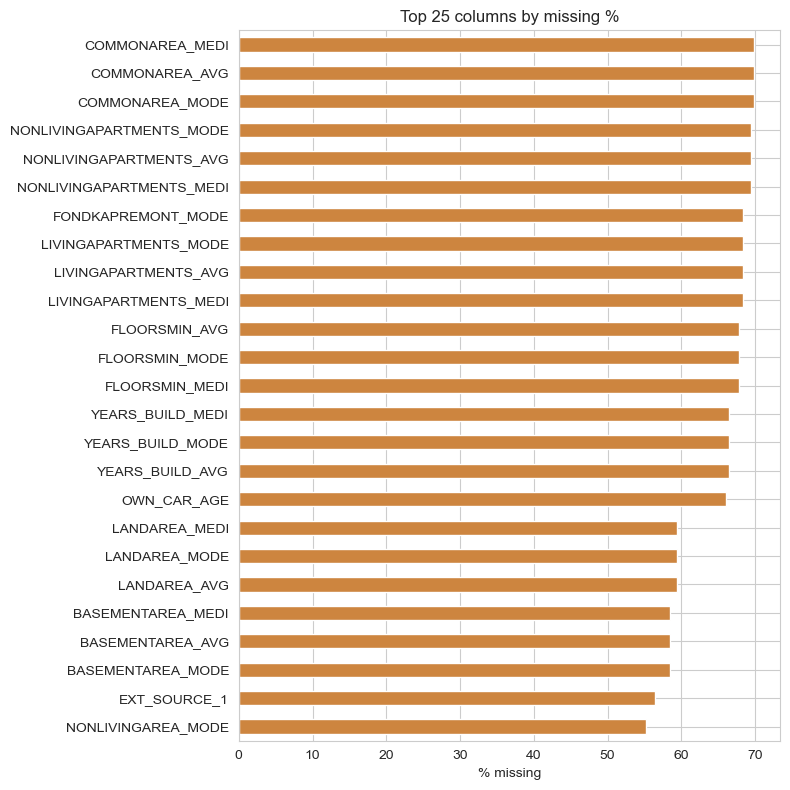

In [5]:
missing = app.isnull().mean().sort_values(ascending=False) * 100
missing = missing[missing > 0]
print('Columns with missing values:', len(missing), 'out of', app.shape[1])

fig, ax = plt.subplots(figsize=(8,8))
missing.head(25).plot(kind='barh', ax=ax, color='peru')
ax.set_xlabel('% missing')
ax.set_title('Top 25 columns by missing %')
ax.invert_yaxis()
plt.tight_layout()
plt.show()



In [6]:
# Known Home Credit data-quality issue: DAYS_EMPLOYED uses 365243 as a sential for "not currently employed"
anomaly_count = (app['DAYS_EMPLOYED'] == 365243).sum()
print(f'DAYS_EMPLOYED == 365243 (sentinel/anomaly): {anomaly_count} rows ({anomaly_count/len(app)*100:.1f}%)')

app['DAYS_EMPLOYED_ANOM'] = (app['DAYS_EMPLOYED'] == 365243).astype('int8')
app['DAYS_EMPLOYED'] = app['DAYS_EMPLOYED'].replace(365243, np.nan)

# CODE_GENDER has a  handful of 'XNA' values - treat as missing
print('CODE_GENDER value counts: \n', app['CODE_GENDER'].value_counts())
app['CODE_GENDER'] = app['CODE_GENDER'].replace('XNA', np.nan)

# Derive human-readable AGE from DAYS_BIRTH
app['AGE_YEARS'] = (-app['DAYS_BIRTH'] / 365.25).astype('float32')

DAYS_EMPLOYED == 365243 (sentinel/anomaly): 55374 rows (18.0%)
CODE_GENDER value counts: 
 CODE_GENDER
F      202448
M      105059
XNA         4
Name: count, dtype: int64


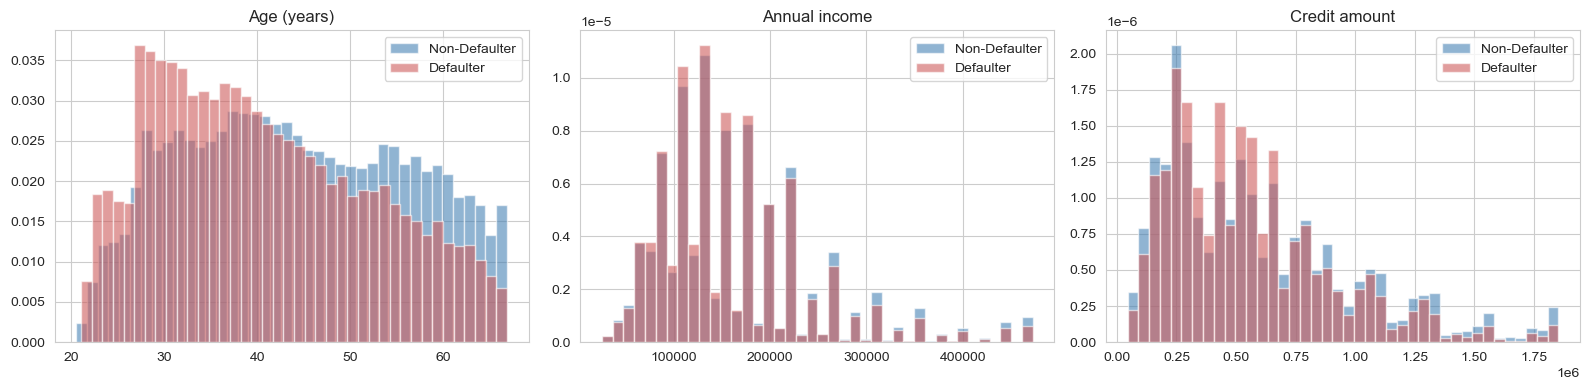

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16,4))
for ax, col, title in zip(
    axes,
    ['AGE_YEARS', 'AMT_INCOME_TOTAL', 'AMT_CREDIT'],
    ['Age (years)', 'Annual income', 'Credit amount']
):
    data0 = app.loc[app.TARGET==0, col].clip(upper=app[col].quantile(0.99))
    data1 = app.loc[app.TARGET==1, col].clip(upper=app[col].quantile(0.99))
    ax.hist(data0, bins=40, alpha=0.6, label='Non-Defaulter', density=True, color='steelblue')
    ax.hist(data1, bins=40, alpha=0.6, label='Defaulter', density=True, color='indianred')
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.show()

**Observation:** defaulters skew younger and have somewhat lower income/credit amounts on average — consistent with the well-known finding that age and external bureau scores are among the strongest predictors in this dataset.

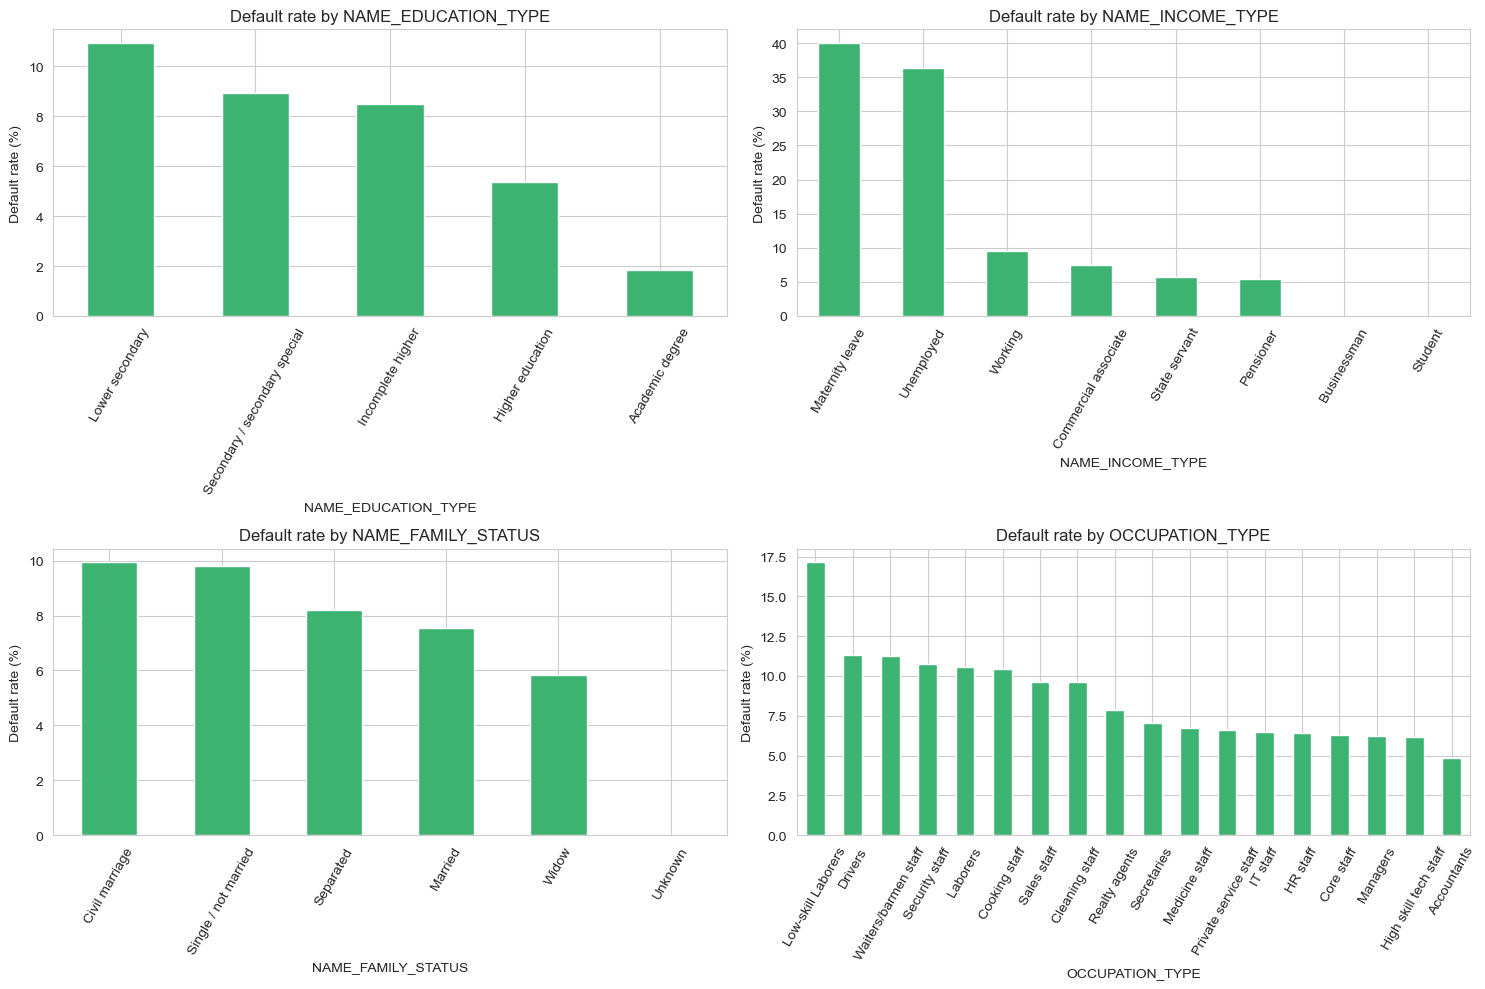

In [8]:
cat_features = ['NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS', 'OCCUPATION_TYPE']
fig, axes = plt.subplots(2, 2, figsize=(15,10))
for ax, col in zip(axes.ravel(), cat_features):
    rate = app.groupby(col)['TARGET'].mean().sort_values(ascending=False) * 100
    rate.plot(kind='bar', ax=ax, color='mediumseagreen')
    ax.set_title(f'Default rate by {col}')
    ax.set_ylabel('Default rate (%)')
    ax.tick_params(axis='x', rotation=60)
plt.tight_layout()
plt.show()

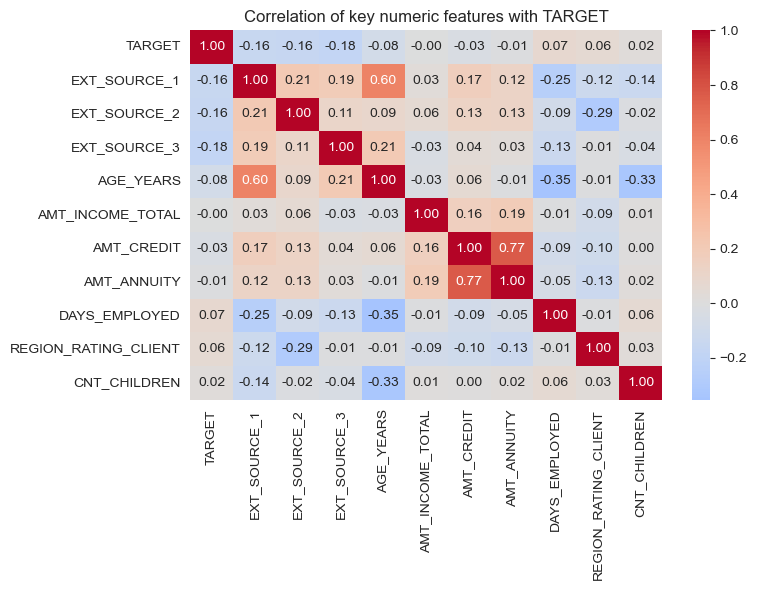

EXT_SOURCE_3           -0.178919
EXT_SOURCE_2           -0.160472
EXT_SOURCE_1           -0.155317
AGE_YEARS              -0.078239
AMT_CREDIT             -0.030369
AMT_ANNUITY            -0.012817
AMT_INCOME_TOTAL       -0.003982
CNT_CHILDREN            0.019187
REGION_RATING_CLIENT    0.058899
DAYS_EMPLOYED           0.074958
TARGET                  1.000000
Name: TARGET, dtype: float64


In [9]:
num_candidates = ['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS', 'AMT_INCOME_TOTAL',
                 'AMT_CREDIT', 'AMT_ANNUITY', 'DAYS_EMPLOYED', 'REGION_RATING_CLIENT', 'CNT_CHILDREN']
corr = app[num_candidates].corr()

fig, ax = plt.subplots(figsize=(8,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation of key numeric features with TARGET')
plt.tight_layout()
plt.show()
print(corr['TARGET'].sort_values())

**Key EDA takeaways (main table):**
- `EXT_SOURCE_1/2/3` (external credit bureau scores) show the strongest correlation with default — by far the most important signal available.
- Younger applicants and those with shorter employment history default more often.
- `NAME_INCOME_TYPE` and `OCCUPATION_TYPE` show meaningful default-rate spread across categories (e.g. unemployed/maternity-leave segments carry higher risk), useful for the customer-segment framing in Task 2.
- The data has real quality issues (`DAYS_EMPLOYED` sentinel, `CODE_GENDER` "XNA") that must be cleaned before modeling — handled above and revisited in the Challenges report.


## 3. Task 1 (Part B) + Task 2 — Supplementary tables: EDA & feature engineering

Each supplementary table is large (up to 27M rows), so every table is **read exactly once**: we inspect its
shape/head/key distributions (the EDA) and immediately aggregate it to one row per `SK_ID_CURR` (the feature
engineering), then discard the raw table (`del` + `gc.collect()`) before moving to the next file. Categorical
columns are read as `category` dtype and numeric columns are downcast to `float32`/`int32` at read time — this
keeps peak memory under ~1 GB per table even though several of the raw files are 300–700 MB on disk.


### 3.1 `bureau_balance.csv` — monthly bureau credit status

`STATUS` is ordinal: `C` = closed/paid off, `X` = unknown, `0`–`5` = number of days-past-due buckets (5 = >120 DPD or written off). We encode it numerically and aggregate to `SK_ID_BUREAU` level.

In [10]:
t0 = time.time()
status_map = {'C': -1, 'X': -2, '0':0, '1':1, '2':2, '3':3, '4':4, '5':5}
dtypes_bb = {'SK_ID_BUREAU':'int32', 'MONTHS_BALANCE':'int16', 'STATUS':'category'}

bb = pd.read_csv(os.path.join(DATA_DIR, 'bureau_balance.csv'), dtype=dtypes_bb)
print('bureau_balance shape:', bb.shape)
display(bb.head())
print(bb['STATUS'].value_counts())

bb['STATUS_NUM'] = bb['STATUS'].map(status_map).astype('float32')
bb['DPD_FLAG'] = (bb['STATUS_NUM'] > 0).astype('int8')

bureau_balance_agg = bb.groupby('SK_ID_BUREAU').agg(
    BB_MONTHS_COUNT=('MONTHS_BALANCE', 'count'),
    BB_MONTHS_MIN=('MONTHS_BALANCE', 'min'),
    BB_STATUS_MAX=('STATUS_NUM', 'max'),
    BB_STATUS_MEAN=('STATUS_NUM', 'mean'),
    BB_DPD_MONTHS=('DPD_FLAG', 'sum')
).reset_index()

del bb; gc.collect()
print('Aggregated to', bureau_balance_agg.shape, '| peak mem: %.2f GB | %.1fs' % (mem_gb(), time.time()-t0))
bureau_balance_agg.to_parquet(f'{ARTIFACT_DIR}/bureau_balance_agg.parquet')

bureau_balance shape: (27299925, 3)


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


STATUS
C    13646993
0     7499507
X     5810482
1      242347
5       62406
2       23419
3        8924
4        5847
Name: count, dtype: int64
Aggregated to (817395, 6) | peak mem: 0.48 GB | 14.0s


### 3.2 `bureau.csv` — previous credits at other institutions

Aggregated to `SK_ID_CURR` level: counts of active/closed credits, exposure sums, overdue behaviour, and the
`bureau_balance` monthly-status features merged in above.

bureau shape: (1716428, 17)


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


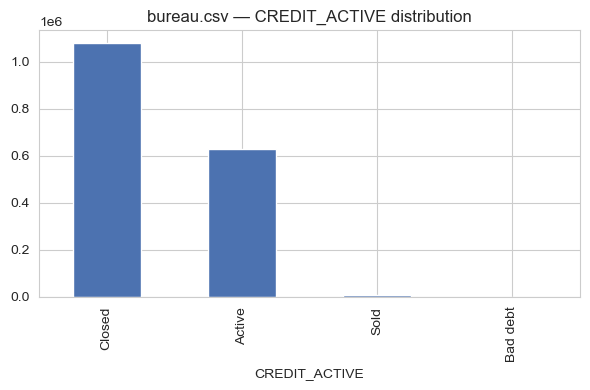

Aggregated to (305811, 22) | peak mem: 0.49 GB | 8.3s


In [11]:
t0 = time.time()
dtypes_bureau = {
    'SK_ID_CURR':'int32','SK_ID_BUREAU':'int32','CREDIT_ACTIVE':'category','CREDIT_CURRENCY':'category',
    'DAYS_CREDIT':'int32','CREDIT_DAY_OVERDUE':'int32','DAYS_CREDIT_ENDDATE':'float32','DAYS_ENDDATE_FACT':'float32',
    'AMT_CREDIT_MAX_OVERDUE':'float32','CNT_CREDIT_PROLONG':'int16','AMT_CREDIT_SUM':'float32',
    'AMT_CREDIT_SUM_DEBT':'float32','AMT_CREDIT_SUM_LIMIT':'float32','AMT_CREDIT_SUM_OVERDUE':'float32',
    'CREDIT_TYPE':'category','DAYS_CREDIT_UPDATE':'int32','AMT_ANNUITY':'float32'
}
bureau = pd.read_csv(os.path.join(DATA_DIR, 'bureau.csv'), dtype=dtypes_bureau)
print('bureau shape:', bureau.shape)
display(bureau.head())

fig, ax = plt.subplots(figsize=(6,4))
bureau['CREDIT_ACTIVE'].value_counts().plot(kind='bar', ax=ax, color='#4C72B0')
ax.set_title('bureau.csv — CREDIT_ACTIVE distribution')
plt.tight_layout(); plt.show()

bureau = bureau.merge(bureau_balance_agg, on='SK_ID_BUREAU', how='left')
del bureau_balance_agg; gc.collect()

bureau['IS_ACTIVE'] = (bureau['CREDIT_ACTIVE']=='Active').astype('int8')
bureau['IS_CLOSED'] = (bureau['CREDIT_ACTIVE']=='Closed').astype('int8')
bureau['DEBT_CREDIT_RATIO'] = (bureau['AMT_CREDIT_SUM_DEBT'] / (bureau['AMT_CREDIT_SUM']+1)).astype('float32')
bureau['OVERDUE_FLAG'] = (bureau['AMT_CREDIT_SUM_OVERDUE'] > 0).astype('int8')

bureau_agg = bureau.groupby('SK_ID_CURR').agg(
    BUREAU_COUNT=('SK_ID_BUREAU','count'),
    BUREAU_ACTIVE_COUNT=('IS_ACTIVE','sum'),
    BUREAU_CLOSED_COUNT=('IS_CLOSED','sum'),
    BUREAU_CREDIT_TYPE_NUNIQUE=('CREDIT_TYPE','nunique'),
    BUREAU_DAYS_CREDIT_MEAN=('DAYS_CREDIT','mean'),
    BUREAU_DAYS_CREDIT_MIN=('DAYS_CREDIT','min'),
    BUREAU_DAYS_CREDIT_ENDDATE_MEAN=('DAYS_CREDIT_ENDDATE','mean'),
    BUREAU_CREDIT_DAY_OVERDUE_MAX=('CREDIT_DAY_OVERDUE','max'),
    BUREAU_AMT_CREDIT_SUM_SUM=('AMT_CREDIT_SUM','sum'),
    BUREAU_AMT_CREDIT_SUM_MEAN=('AMT_CREDIT_SUM','mean'),
    BUREAU_AMT_CREDIT_SUM_DEBT_SUM=('AMT_CREDIT_SUM_DEBT','sum'),
    BUREAU_AMT_CREDIT_SUM_DEBT_MEAN=('AMT_CREDIT_SUM_DEBT','mean'),
    BUREAU_AMT_CREDIT_SUM_LIMIT_SUM=('AMT_CREDIT_SUM_LIMIT','sum'),
    BUREAU_AMT_CREDIT_SUM_OVERDUE_SUM=('AMT_CREDIT_SUM_OVERDUE','sum'),
    BUREAU_OVERDUE_COUNT=('OVERDUE_FLAG','sum'),
    BUREAU_DEBT_CREDIT_RATIO_MEAN=('DEBT_CREDIT_RATIO','mean'),
    BUREAU_CNT_PROLONGED_SUM=('CNT_CREDIT_PROLONG','sum'),
    BUREAU_AMT_ANNUITY_MEAN=('AMT_ANNUITY','mean'),
    BUREAU_BB_STATUS_MAX_MEAN=('BB_STATUS_MAX','mean'),
    BUREAU_BB_DPD_MONTHS_SUM=('BB_DPD_MONTHS','sum'),
    BUREAU_BB_MONTHS_COUNT_MEAN=('BB_MONTHS_COUNT','mean'),
).reset_index()

del bureau; gc.collect()
print('Aggregated to', bureau_agg.shape, '| peak mem: %.2f GB | %.1fs' % (mem_gb(), time.time()-t0))
bureau_agg.to_parquet(f'{ARTIFACT_DIR}/bureau_agg.parquet')


### 3.3 `previous_application.csv` — prior Home Credit applications

Captures each client's history *with Home Credit itself*: how many prior applications, approval/refusal ratio,
and typical requested vs. granted amounts — strong signals for repeat-customer risk.

previous_application shape: (1670214, 18)


,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,RATE_DOWN_PAYMENT,NAME_CONTRACT_STATUS,DAYS_DECISION,CODE_REJECT_REASON,NAME_CLIENT_TYPE,CNT_PAYMENT,NAME_YIELD_GROUP,DAYS_FIRST_DRAWING,DAYS_LAST_DUE,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430054,17145.0,17145.0,0.0,17145.0,0.0,Approved,-73,XAP,Repeater,12.0,middle,365243.0,-42.0,0.0
1,2802425,108129,Cash loans,25188.615234,607500.0,679671.0,NaN,607500.0,NaN,Approved,-164,XAP,Repeater,36.0,low_action,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735352,112500.0,136444.5,NaN,112500.0,NaN,Approved,-301,XAP,Repeater,12.0,high,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335938,450000.0,470790.0,NaN,450000.0,NaN,Approved,-512,XAP,Repeater,12.0,middle,365243.0,-182.0,1.0
4,1784265,202054,Cash loans,31924.394531,337500.0,404055.0,NaN,337500.0,NaN,Refused,-781,HC,Repeater,24.0,high,NaN,NaN,NaN


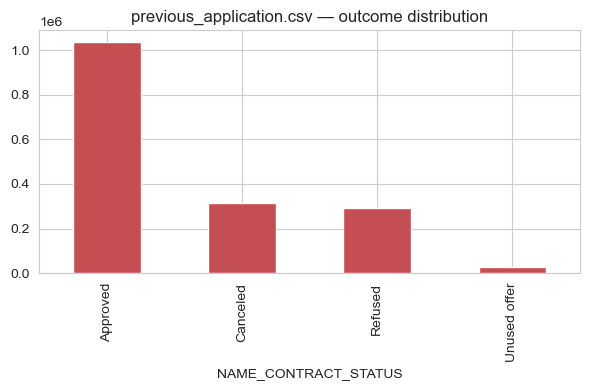

Aggregated to (338857, 18) | peak mem: 0.52 GB | 12.4s


In [12]:
t0 = time.time()
usecols_prev = ['SK_ID_PREV','SK_ID_CURR','NAME_CONTRACT_TYPE','AMT_ANNUITY','AMT_APPLICATION','AMT_CREDIT',
    'AMT_DOWN_PAYMENT','AMT_GOODS_PRICE','NAME_CONTRACT_STATUS','DAYS_DECISION','CODE_REJECT_REASON',
    'NAME_CLIENT_TYPE','CNT_PAYMENT','NAME_YIELD_GROUP','NFLAG_INSURED_ON_APPROVAL','DAYS_FIRST_DRAWING',
    'DAYS_LAST_DUE','RATE_DOWN_PAYMENT']
dtypes_prev = {'SK_ID_PREV':'int32','SK_ID_CURR':'int32','AMT_ANNUITY':'float32','AMT_APPLICATION':'float32',
    'AMT_CREDIT':'float32','AMT_DOWN_PAYMENT':'float32','AMT_GOODS_PRICE':'float32','NAME_CONTRACT_STATUS':'category',
    'DAYS_DECISION':'int32','CODE_REJECT_REASON':'category','NAME_CLIENT_TYPE':'category','CNT_PAYMENT':'float32',
    'NAME_YIELD_GROUP':'category','NFLAG_INSURED_ON_APPROVAL':'float32','DAYS_FIRST_DRAWING':'float32',
    'DAYS_LAST_DUE':'float32','RATE_DOWN_PAYMENT':'float32','NAME_CONTRACT_TYPE':'category'}

prev = pd.read_csv(os.path.join(DATA_DIR, 'previous_application.csv'), usecols=usecols_prev, dtype=dtypes_prev)
print('previous_application shape:', prev.shape)
display(prev.head())

fig, ax = plt.subplots(figsize=(6,4))
prev['NAME_CONTRACT_STATUS'].value_counts().plot(kind='bar', ax=ax, color='#C44E52')
ax.set_title('previous_application.csv — outcome distribution')
plt.tight_layout(); plt.show()

prev['IS_APPROVED'] = (prev['NAME_CONTRACT_STATUS']=='Approved').astype('int8')
prev['IS_REFUSED'] = (prev['NAME_CONTRACT_STATUS']=='Refused').astype('int8')
prev['CREDIT_APPLICATION_RATIO'] = (prev['AMT_CREDIT']/(prev['AMT_APPLICATION']+1)).astype('float32')

previous_app_agg = prev.groupby('SK_ID_CURR').agg(
    PREV_COUNT=('SK_ID_PREV','count'),
    PREV_APPROVED_COUNT=('IS_APPROVED','sum'),
    PREV_REFUSED_COUNT=('IS_REFUSED','sum'),
    PREV_AMT_ANNUITY_MEAN=('AMT_ANNUITY','mean'),
    PREV_AMT_APPLICATION_MEAN=('AMT_APPLICATION','mean'),
    PREV_AMT_CREDIT_MEAN=('AMT_CREDIT','mean'),
    PREV_AMT_CREDIT_SUM=('AMT_CREDIT','sum'),
    PREV_AMT_DOWN_PAYMENT_MEAN=('AMT_DOWN_PAYMENT','mean'),
    PREV_AMT_GOODS_PRICE_MEAN=('AMT_GOODS_PRICE','mean'),
    PREV_DAYS_DECISION_MEAN=('DAYS_DECISION','mean'),
    PREV_DAYS_DECISION_MIN=('DAYS_DECISION','min'),
    PREV_CNT_PAYMENT_MEAN=('CNT_PAYMENT','mean'),
    PREV_CREDIT_APPLICATION_RATIO_MEAN=('CREDIT_APPLICATION_RATIO','mean'),
    PREV_NFLAG_INSURED_MEAN=('NFLAG_INSURED_ON_APPROVAL','mean'),
    PREV_RATE_DOWN_PAYMENT_MEAN=('RATE_DOWN_PAYMENT','mean'),
).reset_index()
previous_app_agg['PREV_APPROVAL_RATIO'] = (previous_app_agg['PREV_APPROVED_COUNT']/previous_app_agg['PREV_COUNT']).astype('float32')
previous_app_agg['PREV_REFUSAL_RATIO'] = (previous_app_agg['PREV_REFUSED_COUNT']/previous_app_agg['PREV_COUNT']).astype('float32')

del prev; gc.collect()
print('Aggregated to', previous_app_agg.shape, '| peak mem: %.2f GB | %.1fs' % (mem_gb(), time.time()-t0))
previous_app_agg.to_parquet(f'{ARTIFACT_DIR}/previous_app_agg.parquet')


### 3.4 `POS_CASH_balance.csv` — monthly POS/cash loan balances

10M rows of monthly history. We summarize each client's payment-delay (`SK_DPD`) behaviour and how many
prior POS/cash loans they carried.

In [13]:
t0 = time.time()
dtypes_pos = {'SK_ID_PREV':'int32','SK_ID_CURR':'int32','MONTHS_BALANCE':'int16','CNT_INSTALMENT':'float32',
    'CNT_INSTALMENT_FUTURE':'float32','NAME_CONTRACT_STATUS':'category','SK_DPD':'int32','SK_DPD_DEF':'int32'}
pos = pd.read_csv(os.path.join(DATA_DIR, 'POS_CASH_balance.csv'), dtype=dtypes_pos)
print('POS_CASH_balance shape:', pos.shape)
display(pos.head())

pos['DPD_FLAG'] = (pos['SK_DPD']>0).astype('int8')
pos['IS_COMPLETED'] = (pos['NAME_CONTRACT_STATUS']=='Completed').astype('int8')

pos_cash_agg = pos.groupby('SK_ID_CURR').agg(
    POS_COUNT=('SK_ID_PREV','count'),
    POS_NUNIQUE_PREV=('SK_ID_PREV','nunique'),
    POS_MONTHS_BALANCE_MIN=('MONTHS_BALANCE','min'),
    POS_CNT_INSTALMENT_MEAN=('CNT_INSTALMENT','mean'),
    POS_CNT_INSTALMENT_FUTURE_MEAN=('CNT_INSTALMENT_FUTURE','mean'),
    POS_SK_DPD_MEAN=('SK_DPD','mean'),
    POS_SK_DPD_MAX=('SK_DPD','max'),
    POS_SK_DPD_DEF_MEAN=('SK_DPD_DEF','mean'),
    POS_SK_DPD_DEF_MAX=('SK_DPD_DEF','max'),
    POS_DPD_FLAG_SUM=('DPD_FLAG','sum'),
    POS_COMPLETED_SUM=('IS_COMPLETED','sum'),
).reset_index()

del pos; gc.collect()
print('Aggregated to', pos_cash_agg.shape, '| peak mem: %.2f GB | %.1fs' % (mem_gb(), time.time()-t0))
pos_cash_agg.to_parquet(f'{ARTIFACT_DIR}/pos_cash_agg.parquet')


POS_CASH_balance shape: (10001358, 8)


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


Aggregated to (337252, 12) | peak mem: 0.54 GB | 19.7s


### 3.5 `credit_card_balance.csv` — monthly credit-card balances

Card utilisation and drawing behaviour are classic revolving-credit risk signals.

In [14]:
t0 = time.time()
dtypes_cc = {'SK_ID_PREV':'int32','SK_ID_CURR':'int32','MONTHS_BALANCE':'int16','AMT_BALANCE':'float32',
    'AMT_CREDIT_LIMIT_ACTUAL':'float32','AMT_DRAWINGS_ATM_CURRENT':'float32','AMT_DRAWINGS_CURRENT':'float32',
    'AMT_DRAWINGS_OTHER_CURRENT':'float32','AMT_DRAWINGS_POS_CURRENT':'float32','AMT_INST_MIN_REGULARITY':'float32',
    'AMT_PAYMENT_CURRENT':'float32','AMT_PAYMENT_TOTAL_CURRENT':'float32','AMT_RECEIVABLE_PRINCIPAL':'float32',
    'AMT_RECIVABLE':'float32','AMT_TOTAL_RECEIVABLE':'float32','CNT_DRAWINGS_ATM_CURRENT':'float32',
    'CNT_DRAWINGS_CURRENT':'float32','CNT_DRAWINGS_OTHER_CURRENT':'float32','CNT_DRAWINGS_POS_CURRENT':'float32',
    'CNT_INSTALMENT_MATURE_CUM':'float32','NAME_CONTRACT_STATUS':'category','SK_DPD':'int32','SK_DPD_DEF':'int32'}
cc = pd.read_csv(os.path.join(DATA_DIR, 'credit_card_balance.csv'), dtype=dtypes_cc)
print('credit_card_balance shape:', cc.shape)
display(cc.head())

cc['CC_DPD_FLAG'] = (cc['SK_DPD']>0).astype('int8')
cc['CC_UTIL_RATIO'] = (cc['AMT_BALANCE']/(cc['AMT_CREDIT_LIMIT_ACTUAL']+1)).astype('float32')

credit_card_agg = cc.groupby('SK_ID_CURR').agg(
    CC_COUNT=('SK_ID_PREV','count'),
    CC_NUNIQUE_PREV=('SK_ID_PREV','nunique'),
    CC_AMT_BALANCE_MEAN=('AMT_BALANCE','mean'),
    CC_AMT_BALANCE_MAX=('AMT_BALANCE','max'),
    CC_AMT_CREDIT_LIMIT_MEAN=('AMT_CREDIT_LIMIT_ACTUAL','mean'),
    CC_AMT_DRAWINGS_ATM_SUM=('AMT_DRAWINGS_ATM_CURRENT','sum'),
    CC_AMT_DRAWINGS_CURRENT_SUM=('AMT_DRAWINGS_CURRENT','sum'),
    CC_AMT_PAYMENT_TOTAL_SUM=('AMT_PAYMENT_TOTAL_CURRENT','sum'),
    CC_AMT_INST_MIN_REGULARITY_MEAN=('AMT_INST_MIN_REGULARITY','mean'),
    CC_CNT_DRAWINGS_CURRENT_MEAN=('CNT_DRAWINGS_CURRENT','mean'),
    CC_SK_DPD_MEAN=('SK_DPD','mean'),
    CC_SK_DPD_MAX=('SK_DPD','max'),
    CC_DPD_FLAG_SUM=('CC_DPD_FLAG','sum'),
    CC_UTIL_RATIO_MEAN=('CC_UTIL_RATIO','mean'),
    CC_UTIL_RATIO_MAX=('CC_UTIL_RATIO','max'),
).reset_index()

del cc; gc.collect()
print('Aggregated to', credit_card_agg.shape, '| peak mem: %.2f GB | %.1fs' % (mem_gb(), time.time()-t0))
credit_card_agg.to_parquet(f'{ARTIFACT_DIR}/credit_card_agg.parquet')


credit_card_balance shape: (3840312, 23)


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,...,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970001,135000.0,0.0,877.5,0.0,877.5,1700.324951,...,0.000000,0.000000,0.0,1.0,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.554688,45000.0,2250.0,2250.0,0.0,0.0,2250.000000,...,64875.554688,64875.554688,1.0,1.0,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.224609,450000.0,0.0,0.0,0.0,0.0,2250.000000,...,31460.085938,31460.085938,0.0,0.0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.109375,225000.0,2250.0,2250.0,0.0,0.0,11795.759766,...,233048.968750,233048.968750,1.0,1.0,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.468750,450000.0,0.0,11547.0,0.0,11547.0,22924.890625,...,453919.468750,453919.468750,0.0,1.0,0.0,1.0,101.0,Active,0,0


Aggregated to (103558, 16) | peak mem: 0.54 GB | 16.5s


### 3.6 `installments_payments.csv` — repayment history

The largest table by row count (13.6M). Payment delay and underpayment ratio here are among the most
predictive engineered features in this style of dataset, since they directly measure repayment discipline.

In [15]:
t0 = time.time()
dtypes_inst = {'SK_ID_PREV':'int32','SK_ID_CURR':'int32','NUM_INSTALMENT_VERSION':'float32','NUM_INSTALMENT_NUMBER':'int32',
    'DAYS_INSTALMENT':'float32','DAYS_ENTRY_PAYMENT':'float32','AMT_INSTALMENT':'float32','AMT_PAYMENT':'float32'}
inst = pd.read_csv(os.path.join(DATA_DIR, 'installments_payments.csv'), dtype=dtypes_inst)
print('installments_payments shape:', inst.shape)
display(inst.head())

inst['PAYMENT_DELAY'] = (inst['DAYS_ENTRY_PAYMENT'] - inst['DAYS_INSTALMENT']).astype('float32')  # >0 = paid late
inst['PAYMENT_RATIO'] = (inst['AMT_PAYMENT'] / (inst['AMT_INSTALMENT']+1)).astype('float32')
inst['UNDERPAID'] = (inst['AMT_PAYMENT'] < inst['AMT_INSTALMENT']).astype('int8')
inst['LATE_FLAG'] = (inst['PAYMENT_DELAY'] > 0).astype('int8')

installments_agg = inst.groupby('SK_ID_CURR').agg(
    INST_COUNT=('SK_ID_PREV','count'),
    INST_PAYMENT_DELAY_MEAN=('PAYMENT_DELAY','mean'),
    INST_PAYMENT_DELAY_MAX=('PAYMENT_DELAY','max'),
    INST_PAYMENT_RATIO_MEAN=('PAYMENT_RATIO','mean'),
    INST_PAYMENT_RATIO_MIN=('PAYMENT_RATIO','min'),
    INST_UNDERPAID_SUM=('UNDERPAID','sum'),
    INST_LATE_FLAG_SUM=('LATE_FLAG','sum'),
    INST_AMT_INSTALMENT_SUM=('AMT_INSTALMENT','sum'),
    INST_AMT_PAYMENT_SUM=('AMT_PAYMENT','sum'),
    INST_AMT_INSTALMENT_MEAN=('AMT_INSTALMENT','mean'),
).reset_index()
installments_agg['INST_LATE_RATIO'] = (installments_agg['INST_LATE_FLAG_SUM']/installments_agg['INST_COUNT']).astype('float32')
installments_agg['INST_UNDERPAID_RATIO'] = (installments_agg['INST_UNDERPAID_SUM']/installments_agg['INST_COUNT']).astype('float32')

del inst; gc.collect()
print('Aggregated to', installments_agg.shape, '| peak mem: %.2f GB | %.1fs' % (mem_gb(), time.time()-t0))
installments_agg.to_parquet(f'{ARTIFACT_DIR}/installments_agg.parquet')


installments_payments shape: (13605401, 8)


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.359863,6948.359863
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525024,1716.525024
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000000,25425.000000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130859,24350.130859
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040039,2160.584961


Aggregated to (339587, 13) | peak mem: 0.56 GB | 24.1s


### 3.7 Merge all engineered features onto `application_train`

In [16]:
t0 = time.time()
df = app.copy()
for name in ['bureau_agg','previous_app_agg','pos_cash_agg','credit_card_agg','installments_agg']:
    part = pd.read_parquet(f'{ARTIFACT_DIR}/{name}.parquet')
    df = df.merge(part, on='SK_ID_CURR', how='left')
    del part; gc.collect()
    print(f'merged {name:<20s} -> {df.shape}')

print('\nFinal engineered dataset:', df.shape, '| peak mem: %.2f GB | %.1fs' % (mem_gb(), time.time()-t0))
df.to_parquet(f'{ARTIFACT_DIR}/final_merged.parquet')
del app; gc.collect()


merged bureau_agg           -> (307511, 145)
merged previous_app_agg     -> (307511, 162)
merged pos_cash_agg         -> (307511, 173)
merged credit_card_agg      -> (307511, 188)
merged installments_agg     -> (307511, 200)

Final engineered dataset: (307511, 200) | peak mem: 0.90 GB | 6.2s


0

In [17]:
# Clients with no history in a supplementary table get NaN counts from the merge — that itself is informative
# (e.g. NaN BUREAU_COUNT means "no bureau history"), so we encode "has history" flags before any imputation.
for prefix, count_col in [('BUREAU','BUREAU_COUNT'), ('PREV','PREV_COUNT'), ('POS','POS_COUNT'),
                           ('CC','CC_COUNT'), ('INST','INST_COUNT')]:
    df[f'HAS_{prefix}_HISTORY'] = df[count_col].notnull().astype('int8')

print('Missing-value rate of the 5 new aggregate count columns (== share of clients with NO prior history):')
for c in ['BUREAU_COUNT','PREV_COUNT','POS_COUNT','CC_COUNT','INST_COUNT']:
    print(f'  {c:<15s}: {df[c].isnull().mean()*100:5.1f}% have no history')


Missing-value rate of the 5 new aggregate count columns (== share of clients with NO prior history):
  BUREAU_COUNT   :  14.3% have no history
  PREV_COUNT     :   5.4% have no history
  POS_COUNT      :   5.9% have no history
  CC_COUNT       :  71.7% have no history
  INST_COUNT     :   5.2% have no history


## 4. Data Preprocessing

- Categorical columns → filled with `'Missing'` and cast to `category` dtype (LightGBM/XGBoost use this natively; for Logistic Regression and Random Forest we additionally derive an integer-encoded copy).
- Numeric columns → left as `NaN` for the boosting models (they split around missing values natively); median-imputed for Logistic Regression and Random Forest.
- Stratified 80/20 train/test split on `TARGET` to preserve the ~8% default rate in both sets.


In [18]:
cat_cols = df.select_dtypes(include=['object']).columns.tolist()
num_cols = [c for c in df.columns if c not in cat_cols + ['TARGET','SK_ID_CURR']]
print(f'{len(cat_cols)} categorical columns, {len(num_cols)} numeric columns, {df.shape[0]} rows')

for c in cat_cols:
    df[c] = df[c].fillna('Missing').astype('category')

X = df.drop(columns=['TARGET','SK_ID_CURR'])
y = df['TARGET'].astype('int8')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Train default rate: %.2f%% | Test default rate: %.2f%%' % (y_train.mean()*100, y_test.mean()*100))


16 categorical columns, 187 numeric columns, 307511 rows
Train: (246008, 203) | Test: (61503, 203)
Train default rate: 8.07% | Test default rate: 8.07%


In [19]:
# Encoded / imputed copy for Logistic Regression & Random Forest (which cannot take NaN or raw categories)
Xtr_enc, Xte_enc = X_train.copy(), X_test.copy()
for c in cat_cols:
    codes_train, uniques = pd.factorize(Xtr_enc[c])
    Xtr_enc[c] = codes_train
    Xte_enc[c] = pd.Categorical(Xte_enc[c], categories=uniques).codes

imputer = SimpleImputer(strategy='median')
Xtr_enc[num_cols] = imputer.fit_transform(Xtr_enc[num_cols])
Xte_enc[num_cols] = imputer.transform(Xte_enc[num_cols])

scaler = StandardScaler()
Xtr_scaled = scaler.fit_transform(Xtr_enc)
Xte_scaled = scaler.transform(Xte_enc)

with open(f"{MODEL_DIR}/median_imputer.pkl", "wb") as f:
    pickle.dump(imputer, f)

with open(f"{MODEL_DIR}/standard_scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)
print('Encoded/imputed/scaled copies ready for Logistic Regression & Random Forest.')


Encoded/imputed/scaled copies ready for Logistic Regression & Random Forest.


## 5. Task 2 — Model Building

Six models are trained and compared:

1. **Logistic Regression** — interpretable linear baseline. Class-imbalance handling: `class_weight='balanced'`.
2. **Decision Tree** — simple nonlinear baseline. Class-imbalance handling: `class_weight='balanced'`.
3. **MLP** — neural-network baseline. **No class-imbalance handling** — scikit-learn's `MLPClassifier` has
   no `class_weight` parameter, so this model is trained on the raw ~8%/92% split (see note below and the
   Model Comparison Report for the effect this has on recall).
4. **Random Forest** — nonlinear baseline with built-in feature importances. Class-imbalance handling: `class_weight='balanced'`.
5. **XGBoost** — gradient boosting, native categorical + missing-value support. Class-imbalance handling: `scale_pos_weight`.
6. **LightGBM** — gradient boosting, histogram-based, native categorical support — the expected best performer
   on this kind of large, sparse, mixed-type tabular data. Class-imbalance handling: `class_weight='balanced'`.

In [20]:
results = {}
timings = {}
models = {}


In [21]:
t0 = time.time()
lr = LogisticRegression(max_iter=300, class_weight='balanced')
lr.fit(Xtr_scaled, y_train)
timings['Logistic Regression'] = time.time() - t0
models['Logistic Regression'] = lr
print('Logistic Regression trained in %.1fs' % timings['Logistic Regression'])


Logistic Regression trained in 13.4s


In [22]:
t0 = time.time()
dt = DecisionTreeClassifier(max_depth=8, class_weight='balanced', random_state=42)
dt.fit(Xtr_enc, y_train)
timings['Decision Tree'] = time.time() - t0
models['Decision Tree'] = dt
print('Decision Tree trained in %.1fs' % timings['Decision Tree'])


Decision Tree trained in 45.1s


In [23]:
t0 = time.time()
mlp = MLPClassifier(hidden_layer_sizes=(64,32), max_iter=40, early_stopping=True, random_state=42)
mlp.fit(Xtr_scaled, y_train)
timings['MLP'] = time.time() - t0
models['MLP'] = mlp
print('MLP trained in %.1fs' % timings['MLP'])


MLP trained in 82.5s


In [24]:
t0 = time.time()
rf = RandomForestClassifier(
    n_estimators=100, max_depth=9, class_weight='balanced',
    n_jobs=-1, random_state=RANDOM_STATE)
rf.fit(Xtr_enc, y_train)
timings['Random Forest'] = time.time() - t0
models['Random Forest'] = rf
print('Random Forest trained in %.1fs' % timings['Random Forest'])


Random Forest trained in 79.3s


In [25]:
t0 = time.time()
scale_pos_weight = (y_train==0).sum() / (y_train==1).sum()
xgb_model = xgb.XGBClassifier(
    n_estimators=200, learning_rate=0.07, max_depth=6,
    scale_pos_weight=scale_pos_weight, tree_method='hist',
    enable_categorical=True, random_state=RANDOM_STATE, eval_metric='auc')
xgb_model.fit(X_train, y_train)
timings['XGBoost'] = time.time() - t0
models['XGBoost'] = xgb_model
print('XGBoost trained in %.1fs' % timings['XGBoost'])


XGBoost trained in 66.0s


In [26]:
t0 = time.time()
lgbm_model = lgb.LGBMClassifier(
    n_estimators=200, learning_rate=0.07, num_leaves=31,
    class_weight='balanced', random_state=RANDOM_STATE, verbosity=-1)
lgbm_model.fit(X_train, y_train, categorical_feature=cat_cols)
timings['LightGBM'] = time.time() - t0
models['LightGBM'] = lgbm_model
print('LightGBM trained in %.1fs' % timings['LightGBM'])


LightGBM trained in 46.2s


## 6. Model Evaluation & Comparison Report

In [27]:
def evaluate(name, model, Xte, y_true, threshold=0.5):
    proba = model.predict_proba(Xte)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        'Model': name,
        'ROC-AUC': roc_auc_score(y_true, proba),
        'PR-AUC': average_precision_score(y_true, proba),
        'Accuracy': accuracy_score(y_true, pred),
        'Precision': precision_score(y_true, pred),
        'Recall': recall_score(y_true, pred),
        'F1': f1_score(y_true, pred),
        'Train time (s)': timings[name],
    }, proba

rows = []
probas = {}
eval_inputs = {
    'Logistic Regression': Xte_scaled,
    'Random Forest': Xte_enc,
    'Decision Tree': Xte_enc,
    'MLP': Xte_scaled,
    'XGBoost': X_test,
    'LightGBM': X_test,
}
for name, model in models.items():
    row, proba = evaluate(name, model, eval_inputs[name], y_test)
    rows.append(row)
    probas[name] = proba

comparison_df = pd.DataFrame(rows).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
comparison_df


,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,Train time (s)
0,LightGBM,0.780313,0.279443,0.738322,0.188386,0.677543,0.294803,46.200069
1,XGBoost,0.777089,0.273418,0.756809,0.194733,0.641893,0.298814,66.040279
2,Logistic Regression,0.765666,0.249678,0.645578,0.154396,0.757301,0.256498,13.372941
3,Random Forest,0.747896,0.224786,0.745362,0.180220,0.607049,0.277929,79.289039
4,MLP,0.733937,0.209542,0.919370,0.625000,0.003021,0.006013,82.479516
5,Decision Tree,0.715581,0.190926,0.644017,0.143645,0.687210,0.237621,45.099152


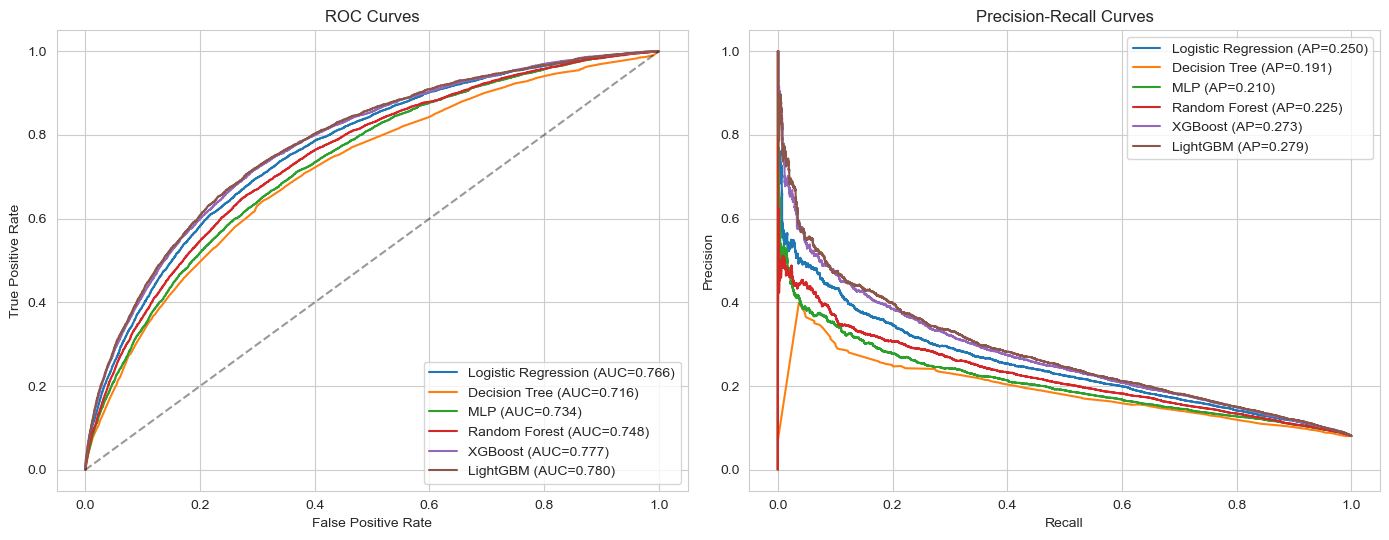

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14,5.5))

for name, proba in probas.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    axes[0].plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')
axes[0].plot([0,1],[0,1],'k--', alpha=0.4)
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves'); axes[0].legend()

for name, proba in probas.items():
    prec, rec, _ = precision_recall_curve(y_test, proba)
    ap = average_precision_score(y_test, proba)
    axes[1].plot(rec, prec, label=f'{name} (AP={ap:.3f})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves'); axes[1].legend()

plt.tight_layout(); plt.show()


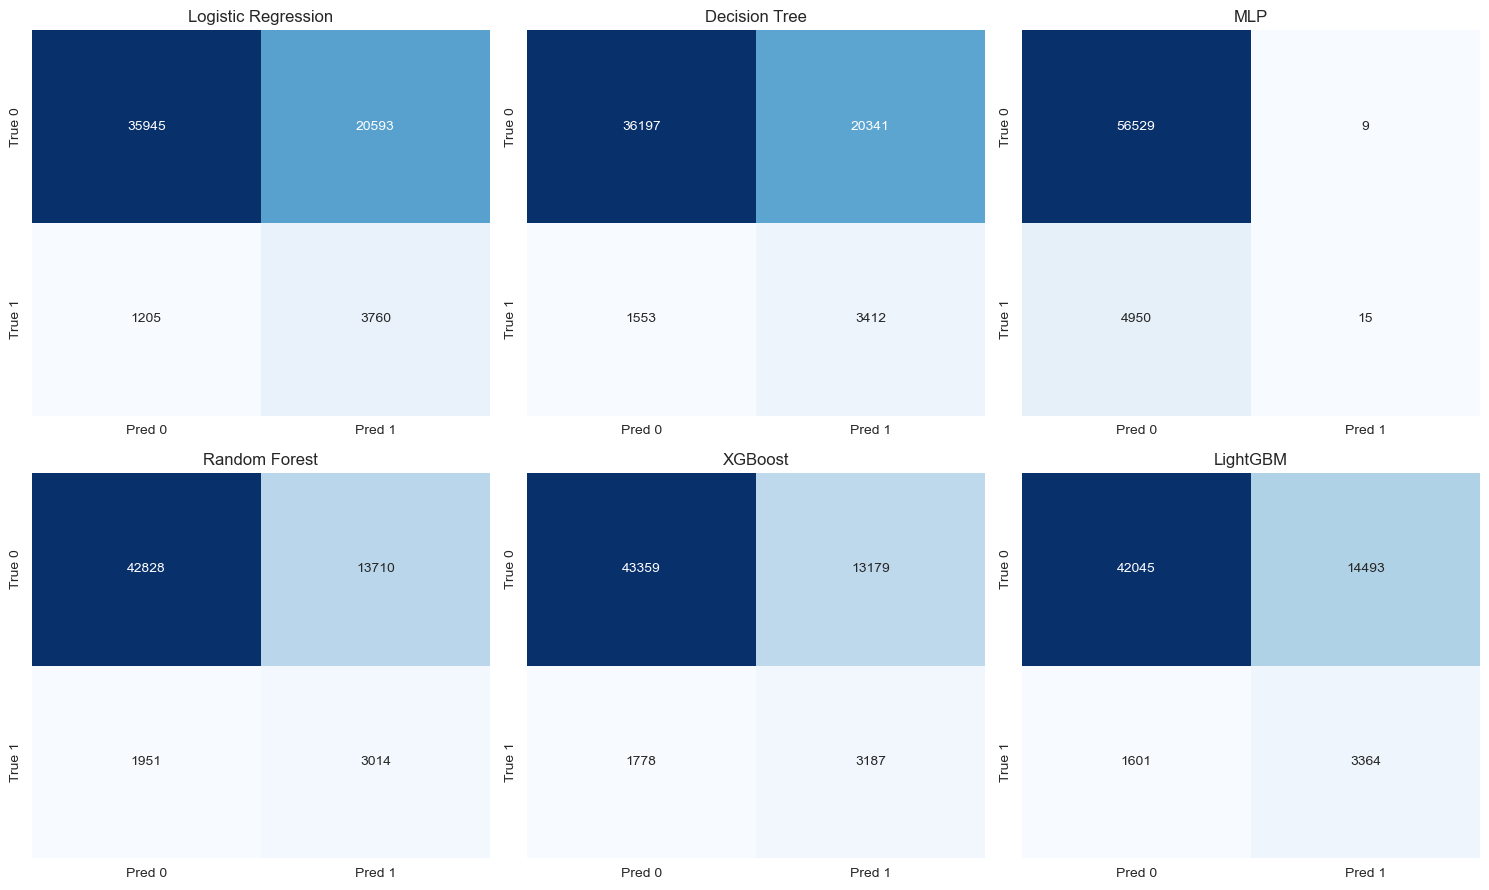

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(15,9))
axes = axes.flatten()

for ax, (name, proba) in zip(axes, probas.items()):
    pred = (proba >= 0.5).astype(int)
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred 0', 'Pred 1'], yticklabels=['True 0', 'True 1'])
    ax.set_title(name)
plt.tight_layout()
plt.show()


In [30]:
best_model_name = comparison_df.iloc[0]['Model']
best_model = models[best_model_name]
print('='*70)
print(f'BEST MODEL BY ROC-AUC: {best_model_name}')
print('='*70)
print(comparison_df.to_string(index=False))


BEST MODEL BY ROC-AUC: LightGBM
              Model  ROC-AUC   PR-AUC  Accuracy  Precision   Recall       F1  Train time (s)
           LightGBM 0.780313 0.279443  0.738322   0.188386 0.677543 0.294803       46.200069
            XGBoost 0.777089 0.273418  0.756809   0.194733 0.641893 0.298814       66.040279
Logistic Regression 0.765666 0.249678  0.645578   0.154396 0.757301 0.256498       13.372941
      Random Forest 0.747896 0.224786  0.745362   0.180220 0.607049 0.277929       79.289039
                MLP 0.733937 0.209542  0.919370   0.625000 0.003021 0.006013       82.479516
      Decision Tree 0.715581 0.190926  0.644017   0.143645 0.687210 0.237621       45.099152


## 7. Feature Importance — which factors drive loan eligibility / default risk

Using the best model's built-in feature importances plus SHAP values (on a sample of the test set, to keep
runtime manageable) to identify the factors and customer segments most associated with default — directly
answering the "identify the factors / customer segments eligible for taking loan" part of Task 2.


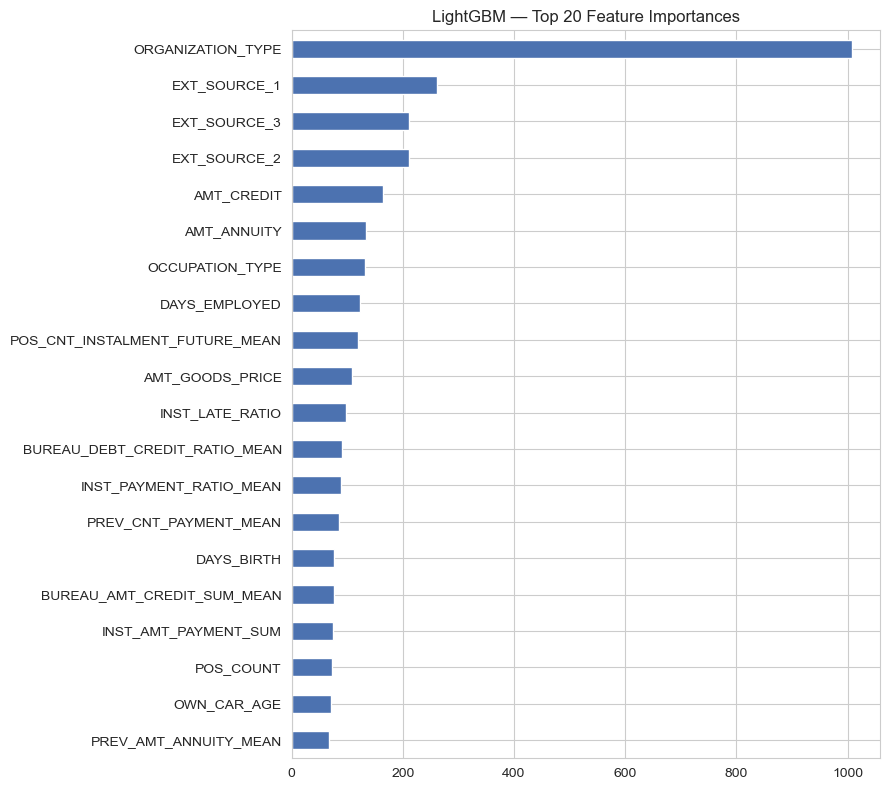

ORGANIZATION_TYPE                 1008
EXT_SOURCE_1                       261
EXT_SOURCE_3                       212
EXT_SOURCE_2                       211
AMT_CREDIT                         164
AMT_ANNUITY                        134
OCCUPATION_TYPE                    132
DAYS_EMPLOYED                      123
POS_CNT_INSTALMENT_FUTURE_MEAN     120
AMT_GOODS_PRICE                    109
INST_LATE_RATIO                     97
BUREAU_DEBT_CREDIT_RATIO_MEAN       90
INST_PAYMENT_RATIO_MEAN             88
PREV_CNT_PAYMENT_MEAN               86
DAYS_BIRTH                          76
BUREAU_AMT_CREDIT_SUM_MEAN          76
INST_AMT_PAYMENT_SUM                74
POS_COUNT                           72
OWN_CAR_AGE                         71
PREV_AMT_ANNUITY_MEAN               68
dtype: int32


In [31]:
importances = pd.Series(best_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9,8))
importances.head(20).sort_values().plot(kind='barh', ax=ax, color='#4C72B0')
ax.set_title(f'{best_model_name} — Top 20 Feature Importances')
plt.tight_layout(); plt.show()

print(importances.head(20))


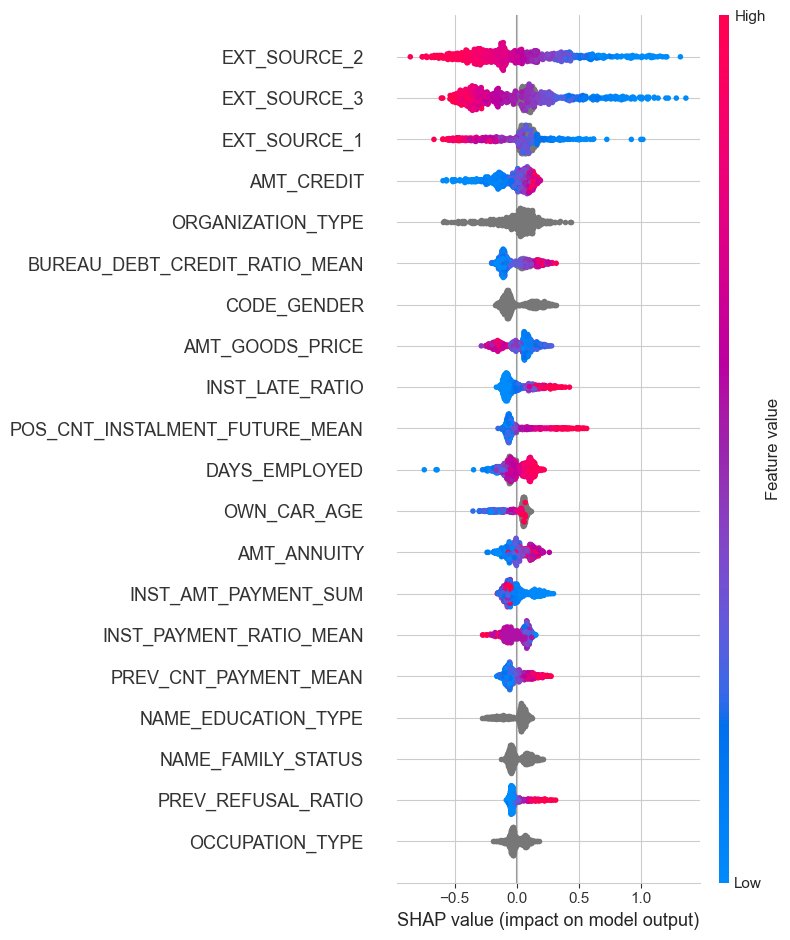

In [32]:
# SHAP on a sample of the test set (SHAP is expensive on the full 61k-row test set)
shap_sample = X_test.sample(n=min(800, len(X_test)), random_state=RANDOM_STATE)

if best_model_name in ('LightGBM','XGBoost','Random Forest', ):
    explainer = shap.TreeExplainer(best_model)
    shap_values = explainer.shap_values(shap_sample)
    if isinstance(shap_values, list):
        shap_values = shap_values[1]
else:
    explainer = shap.LinearExplainer(best_model, Xtr_scaled)
    shap_values = explainer.shap_values(scaler.transform(shap_sample))

shap.summary_plot(shap_values, shap_sample, max_display=20, show=False)
plt.tight_layout(); plt.show()


**Interpretation — factors & segments associated with eligibility / risk:**

- The external bureau scores (`EXT_SOURCE_1/2/3`) dominate feature importance and SHAP magnitude — applicants
  with low external scores are the highest-risk segment regardless of any other factor.
- Repayment-discipline features engineered from `installments_payments` (late-payment ratio, underpayment ratio)
  and bureau overdue behaviour (`BUREAU_OVERDUE_COUNT`, `BUREAU_DEBT_CREDIT_RATIO_MEAN`) rank highly — clients
  with a track record of on-time repayment on *previous* credit (with Home Credit or elsewhere) are
  substantially more loan-eligible.
- `AGE_YEARS` / `DAYS_BIRTH` and `DAYS_EMPLOYED` contribute meaningfully — younger applicants with short or
  anomalous employment history form a higher-risk segment.
- Prior-application behaviour with Home Credit itself (`PREV_REFUSAL_RATIO`, `PREV_APPROVAL_RATIO`) is
  predictive — clients previously refused are more likely to default if approved again, all else equal.
- **Practical eligibility segment:** applicants with high `EXT_SOURCE` scores, a clean bureau/installment
  repayment history, stable long-term employment, and no prior refusals form the clearly low-risk / most
  loan-eligible segment; the inverse combination flags the segment needing manual underwriting review or decline.


## 8. Hyperparameter Tuning

In [33]:
# LightGBM

lgb_param_grid = {
    'n_estimators': randint(100, 600),
    'learning_rate': loguniform(0.01, 0.2),
    'num_leaves': randint(15, 100),
    'max_depth': [-1, 5, 7, 10, 15],
    'min_child_samples': randint(10, 100),
    'subsample': uniform(0.6, 0.4),
    'colsample_bytree': uniform(0.6, 0.4),
    'reg_alpha': loguniform(1e-4, 10),
    'reg_lambda': loguniform(0.1, 10)
}

lgb_random = RandomizedSearchCV(
    estimator=lgb.LGBMClassifier(
        class_weight='balanced',
        random_state=RANDOM_STATE,
        verbosity=-1
    ),
    param_distributions=lgb_param_grid,
    n_iter=20,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

t0_tune = time.time() 

lgb_random.fit(
    X_train,
    y_train,
    categorical_feature=cat_cols
)

timings['LightGBM(Tuned)'] = time.time() - t0_tune 

print("Best LightGBM Parameters:")
print(lgb_random.best_params_)

print("Best CV ROC-AUC:")
print(lgb_random.best_score_)

best_lgb = lgb_random.best_estimator_

tuned_models = {
    'LightGBM(Tuned)': (best_lgb, X_test)
}

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best LightGBM Parameters:
{'colsample_bytree': np.float64(0.9464704583099741), 'learning_rate': np.float64(0.06054365855469246), 'max_depth': 7, 'min_child_samples': 31, 'n_estimators': 408, 'num_leaves': 16, 'reg_alpha': np.float64(0.40737451960583815), 'reg_lambda': np.float64(7.535384509295546), 'subsample': np.float64(0.6003115063364057)}
Best CV ROC-AUC:
0.7773288652367237


In [34]:
for name, (model, X_eval) in tuned_models.items():
    y_proba = model.predict_proba(X_eval)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)

    rows.append({
        'Model': name,
        'ROC-AUC': roc_auc_score(y_test, y_proba),
        'PR-AUC': average_precision_score(y_test, y_proba),
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'Train time (s)': timings[name]
    })

tuned_comparison_df = (
    pd.DataFrame(rows)
    .sort_values('ROC-AUC', ascending=False)
    .reset_index(drop=True)
)
tuned_comparison_df

,Model,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1,Train time (s)
0,LightGBM(Tuned),0.782303,0.282813,0.737558,0.189141,0.684794,0.296413,2910.449867
1,LightGBM,0.780313,0.279443,0.738322,0.188386,0.677543,0.294803,46.200069
2,XGBoost,0.777089,0.273418,0.756809,0.194733,0.641893,0.298814,66.040279
3,Logistic Regression,0.765666,0.249678,0.645578,0.154396,0.757301,0.256498,13.372941
4,Random Forest,0.747896,0.224786,0.745362,0.180220,0.607049,0.277929,79.289039
5,MLP,0.733937,0.209542,0.919370,0.625000,0.003021,0.006013,82.479516
6,Decision Tree,0.715581,0.190926,0.644017,0.143645,0.687210,0.237621,45.099152


## 9. Save Models

In [35]:
# Create models folder
os.makedirs(MODEL_DIR, exist_ok=True)

# Save best tuned LightGBM model
with open(f'{MODEL_DIR}/best_model.pkl', 'wb') as f:
    pickle.dump(best_lgb, f)

print("Best model saved successfully!")

Best model saved successfully!


### Sample Example

In [36]:
# Load the saved model
with open(f'{MODEL_DIR}/best_model.pkl', 'rb') as f:
    best_model = pickle.load(f)

print("Best model loaded successfully!")

Best model loaded successfully!


In [37]:
# Take one sample from X_test
sample = X_test.iloc[[0]]
print("Sample shape:", sample.shape)

# Prediction probability
probability = best_model.predict_proba(sample)[0][1]

# Prediction
prediction = best_model.predict(sample)[0]

print("Prediction:", prediction)
print(f"Default Probability: {probability:.2%}")

if prediction == 1:
    print("Result: Customer is likely to DEFAULT")
else:
    print("Result: Customer is likely to NOT DEFAULT")

Sample shape: (1, 203)
Prediction: 0
Default Probability: 34.34%
Result: Customer is likely to NOT DEFAULT


## 10. Model Comparison Report

Six classification models were evaluated for predicting home-loan default risk: Logistic Regression, Decision Tree, Random Forest, MLP, XGBoost, and LightGBM. Because the target variable is highly imbalanced, with only about 8% of applicants being defaulters, ROC-AUC and PR-AUC were considered more informative than accuracy alone.

| Model               |    ROC-AUC |     PR-AUC |   Accuracy |  Precision |     Recall |   F1-Score |
| ------------------- | ---------: | ---------: | ---------: | ---------: | ---------: | ---------: |
| LightGBM            | **0.7803** | **0.2794** |     0.7383 |     0.1884 |     0.6775 |     0.2948 |
| XGBoost             |     0.7771 |     0.2734 |     0.7568 | **0.1947** |     0.6419 | **0.2988** |
| Logistic Regression |     0.7657 |     0.2497 |     0.6456 |     0.1544 | **0.7573** |     0.2565 |
| Random Forest       |     0.7479 |     0.2248 |     0.7454 |     0.1802 |     0.6070 |     0.2779 |
| MLP                 |     0.7339 |     0.2095 | **0.9194** | **0.6250** |     0.0030 |     0.0060 |
| Decision Tree       |     0.7156 |     0.1909 |     0.6440 |     0.1436 |     0.6872 |     0.2376 |

### Key Findings

**LightGBM** achieved the highest ROC-AUC of **0.7803** and PR-AUC of **0.2794**, making it the strongest overall model for ranking applicants according to default risk.

**XGBoost** was a close second, with ROC-AUC of **0.7771**. It achieved the highest F1-score (**0.2988**) and slightly higher precision than LightGBM.

**Logistic Regression** achieved the highest recall (**0.7573**), meaning it identified the largest proportion of actual defaulters. It is also useful as an interpretable baseline model.

**Random Forest** performed moderately well but was weaker than the boosting models on ROC-AUC and PR-AUC.

**MLP** produced high accuracy (**91.94%**) but extremely low recall (**0.30%**). This demonstrates why accuracy is not an appropriate standalone metric for this highly imbalanced dataset. The model largely failed to identify defaulters.

**Decision Tree** had the lowest ROC-AUC (**0.7156**) and PR-AUC (**0.1909**) among the evaluated models.

### Final Model Selection

| Model               |    ROC-AUC |     PR-AUC |   Accuracy |  Precision |     Recall |   F1-Score |
| ------------------- | ---------: | ---------: | ---------: | ---------: | ---------: | ---------: |
| LightGBM(Tuned)     | **0.7823** | **0.2828** |     0.7375 |     0.1891 |     0.6847 |     0.2964 |
| LightGBM            | **0.7803** | **0.2794** |     0.7383 |     0.1884 |     0.6775 |     0.2948 |
| XGBoost             |     0.7771 |     0.2734 |     0.7568 | **0.1947** |     0.6419 | **0.2988** |
| Logistic Regression |     0.7657 |     0.2497 |     0.6456 |     0.1544 | **0.7573** |     0.2565 |

LightGBM was selected as the recommended production model because it provided the highest ROC-AUC and PR-AUC while also having substantially lower training time than Random Forest and MLP.

The model was further tuned using `RandomizedSearchCV` with 20 parameter combinations and 3-fold cross-validation. The tuned LightGBM achieved a cross-validation ROC-AUC of approximately **0.7773**.

For a credit-default problem, the final production threshold should be selected according to the business cost of false negatives and false positives rather than automatically relying on the default 0.5 threshold.


### 11. Challenges Faced Report

During the development of the Home Loan Default Prediction project, several technical and modeling challenges were encountered.

#### 1. Large Dataset and Memory Constraints

The project contains seven raw CSV files totaling approximately 2.9 GB, with `bureau_balance.csv` containing around 27 million rows.

**Solution:**
Each supplementary table was processed one at a time. Categorical columns were loaded using `category` dtype and numerical columns were downcast to smaller data types such as `float32`, `int32`, and `int16`. The data was immediately aggregated and the raw table was deleted using garbage collection before processing the next table.

This significantly reduced memory usage while allowing all supplementary data to be incorporated.

#### 2. Multi-Table Data Integration

The project involved combining information from six supplementary tables with the main application table. These tables had different levels of granularity, including monthly records, previous applications, bureau records, and installment payments.

**Solution:**
The supplementary data was aggregated to the customer level using `SK_ID_CURR`. For bureau data, a two-stage aggregation was performed: `bureau_balance` was first aggregated to `SK_ID_BUREAU`, merged with bureau information, and then aggregated to `SK_ID_CURR`.

This allowed historical credit information to be converted into meaningful customer-level features.

#### 3. Severe Class Imbalance

Only approximately 8% of applications belonged to the default class. A model could therefore achieve high accuracy while performing poorly at identifying actual defaulters.

**Solution:**
Class weighting was used for Logistic Regression, Random Forest, Decision Tree and LightGBM, while XGBoost used `scale_pos_weight`. Model performance was evaluated using ROC-AUC, PR-AUC, precision, recall, and F1-score instead of relying only on accuracy.

#### 4. Missing Values

The dataset contains a large number of missing values. Some missing values represent genuinely unavailable information, while others indicate that a customer has no previous credit history.

**Solution:**
History-indicator features such as `HAS_<TABLE>_HISTORY` were created. Median imputation was used for models that required complete numeric data, while boosting models were allowed to handle missing values natively.

#### 5. Data-Quality Issues

The `DAYS_EMPLOYED` column contains the sentinel value `365243` for a significant group of applicants. Treating this value as a normal number would incorrectly indicate an extremely long employment period. The `CODE_GENDER` column also contained `XNA` values.

**Solution:**
The `365243` value was converted to missing and an anomaly indicator was created. The `XNA` gender values were also converted to missing before encoding.

#### 6. Different Model Preprocessing Requirements

Different algorithms require different data formats. Logistic Regression requires numerical and scaled features, while Random Forest requires numerical values without missing values. LightGBM and XGBoost can work with missing values and categorical information more naturally.

**Solution:**
Separate feature representations were maintained for different model families. Categorical features were converted appropriately, numerical features were imputed where required, and scaling was applied to models that benefit from it.

#### 7. Large Number of Engineered Features

Combining the main application table with six supplementary sources resulted in approximately 200 client-level features.

**Solution:**
Meaningful aggregations such as counts, means, sums, maximums, delinquency measures, utilization ratios, approval/refusal ratios, and repayment indicators were created. Feature importance and SHAP analysis were then used to understand which features contributed most to predictions.


### 12. Conclusion

The Home Loan Default Prediction project successfully developed an end-to-end machine learning pipeline for identifying applicants who are at higher risk of loan default.

The project integrated the main application data with six supplementary credit-history tables and transformed millions of historical records into approximately 200 customer-level features. Memory-efficient processing, aggregation, data cleaning, missing-value handling, categorical encoding, and class-imbalance techniques were applied to make the dataset suitable for machine learning.

Multiple classification algorithms were evaluated, including Logistic Regression, Decision Tree, Random Forest, MLP, XGBoost, and LightGBM. Among these models, **LightGBM achieved the best overall ROC-AUC (0.7803) and PR-AUC (0.2794)** and was therefore selected as the recommended production model. XGBoost performed very closely and achieved the highest F1-score, while Logistic Regression provided the highest recall and an interpretable baseline.

Feature-importance and SHAP analysis showed that **external credit scores (`EXT_SOURCE_1`, `EXT_SOURCE_2`, and `EXT_SOURCE_3`) were the strongest predictors of default risk**. Repayment behaviour, bureau overdue history, installment-payment discipline, employment history, age, and previous Home Credit application outcomes were also important factors.

The results indicate that applicants with stronger external credit scores, stable employment, good repayment history, and fewer previous application refusals are generally associated with lower default risk. Applicants showing the opposite pattern can be identified for additional review or stricter underwriting.

Hyperparameter tuning was also performed on LightGBM using randomized search and 3-fold cross-validation. The tuned model can be further improved by optimizing the classification threshold according to the business cost of false negatives and false positives.

Overall, the project demonstrates how large-scale historical credit data can be transformed into actionable features and used to support data-driven loan-risk assessment. The resulting model can serve as a decision-support tool for financial institutions while keeping human review and appropriate credit-risk policies in the decision process.
